# K-Means baseline từ raw — Online Retail

## Tóm tắt

Notebook chính để đọc và chạy toàn bộ baseline: **raw → cleaning → RFM →
log1p → StandardScaler → K-Means → đánh giá → hồ sơ cụm**.

**Cách dùng:** chọn kernel Python đã cài [requirements.txt](../../requirements.txt),
rồi **Restart Kernel → Run All**. Hướng dẫn môi trường ở [README](../../README.md#cài-đặt).
Mã từng bước nằm ngay bên dưới; các hàm xử lý dùng chung với CLI trong `src/`.
Đây là notebook trong repository, cần giữ thư mục `src/`, cấu hình và raw khi chạy lại.

Từ **541,909 dòng raw**, chính sách thử nghiệm giữ **392,692 dòng mua**, tổng hợp **4,338 khách** và chọn **k=2** trong dải đã khảo sát. Silhouette đạt **0.432509**, Davies–Bouldin **0.891265**.

## Bối cảnh và phương pháp

Mục tiêu là phân nhóm khách theo hành vi mua lịch sử, không giám sát và không có nhãn thật.
Notebook chạy lại **cấu hình thử nghiệm riêng đã có**, chưa thay quyết định chính thức của nhóm.
Kết quả và biểu đồ được lưu trong output notebook; không ghi đè dữ liệu hay artifact của CLI.

### Các giả định

- Nguồn duy nhất: `data/raw/Online Retail.xlsx`, sheet `Online Retail`; kiểm tra SHA-256 trước khi đọc.
- Bỏ dòng trùng hoàn toàn trên 8 cột raw, khách thiếu mã, chứng từ bắt đầu bằng C,
  Quantity hoặc UnitPrice không dương. Giữ tất cả quốc gia, mã dịch vụ và ngoại lệ.
- Cửa sổ `[2010-12-01, 2011-12-10)`; ngày tham chiếu 10/12/2011; không tự gán múi giờ cho ngày nguồn.
- Monetary là giá trị mua dương (GBP), gồm dịch vụ, chưa đối trừ hoàn trả; không phải lợi nhuận hay CLV.
- Chỉ RFM tham gia phân cụm. CustomerID, Country và các biến hành vi bổ sung không đi vào ma trận mô hình.
- Chọn k có Silhouette cao nhất trên toàn bộ khách trong dải 2–10;
  Elbow, Davies–Bouldin và hồ sơ cụm hỗ trợ diễn giải. Seed 42, n_init=20.
- Các chỉ số được tính trên chính tập fit, chưa có holdout độc lập và chưa kiểm tra độ ổn định theo nhiều seed.

Tài liệu: [cấu hình](../../configs/kmeans_k4.yaml),
[báo cáo tiến độ](../../reports/bao_cao_tien_do.md),
[quy ước dữ liệu](../../AGENTS.md).

### 1. Nạp thư viện và xác định thư mục dự án

Có thể mở notebook từ gốc repository, `project/` hoặc thư mục chứa notebook.
Cell này dùng cùng các hàm cleaning, feature, fit và đánh giá với CLI.

In [1]:
from datetime import datetime, timedelta, timezone
from pathlib import Path
import importlib.metadata
import json
import platform
import sys

candidates = [candidate for parent in [Path.cwd(), *Path.cwd().parents]
              for candidate in [parent, parent / "project"]
              if (candidate / "src/run_experiment.py").is_file()
              and (candidate / "configs/kmeans_k4.yaml").is_file()]
if not candidates:
    raise FileNotFoundError("Mở notebook trong repository có project/src và project/configs.")
project = candidates[0].resolve()
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

from src.preprocessing import RAW_PATH, clean_purchases, load_raw, sha256_of
from src.models import fit_kmeans
from src.evaluation import evaluate_clustering
from src.run_experiment import make_customer_features, manual_rfm_checks, read_config

# Bật backend inline sau khi import runner CLI (runner dùng backend Agg).
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, StrMethodFormatter

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 12)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlepad": 10, "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.facecolor": "white"})
BLUE, ORANGE, NEUTRAL = "#2266a0", "#b95e14", "#444444"
print(f"Project: {project.name} | Python {platform.python_version()}")

Project: project | Python 3.12.15


### 2. Đọc cấu hình và ghi nhận nguồn

Tên `kmeans_k4.yaml` là tên lịch sử; đọc `k_values` bên dưới để biết dải khảo sát thực tế.
Lưu hash trước khi tính để kiểm tra cuối notebook rằng raw, processed và kết quả CLI không bị đổi.

In [2]:
config, config_path = read_config(project / "configs/kmeans_k4.yaml")
RFM = list(config["features"])
baseline_dir = project / config["output_dir"]
protected_paths = [RAW_PATH, *sorted((project / "data/processed").rglob("*")),
                   *sorted(baseline_dir.rglob("*"))]
protected_before = {p: sha256_of(p) for p in protected_paths if p.is_file()}
assert protected_before[RAW_PATH] == config["raw_sha256"], "Raw không khớp phiên bản được phép."

execution_record = {
    "executed_at": datetime.now(timezone(timedelta(hours=7))).isoformat(),
    "python": platform.python_version(), "raw_path": config["raw_path"],
    "sheet": config["sheet"], "raw_sha256": protected_before[RAW_PATH],
    "config_sha256": sha256_of(config_path),
    "library_versions": {name: importlib.metadata.version(name)
                         for name in ["numpy", "pandas", "scikit-learn", "scipy",
                                      "matplotlib", "openpyxl", "PyYAML", "threadpoolctl"]},
}
display(pd.DataFrame({"Tham số": list(config), "Giá trị": [str(v) for v in config.values()]}))
print("Raw SHA-256:", execution_record["raw_sha256"])
display(pd.DataFrame(execution_record["library_versions"].items(), columns=["Thư viện", "Phiên bản"]))

,Tham số,Giá trị
0,run_id,rfm_kmeans_experimental_v1
1,status,experimental
2,authorization,User selected the isolated experimental config...
3,raw_path,data/raw/Online Retail.xlsx
4,raw_sha256,43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93...
...,...,...
13,selection,highest_full_population_silhouette
14,random_state,42
15,n_init,20
16,max_iter,300


Raw SHA-256: 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d


,Thư viện,Phiên bản
0,numpy,2.5.4
1,pandas,3.1.0
2,scikit-learn,1.9.1
3,scipy,1.18.1
4,matplotlib,3.11.2
5,openpyxl,3.1.5
6,PyYAML,6.0.3
7,threadpoolctl,3.7.0


## Dữ liệu

### 3. Đọc và kiểm kê raw

Một dòng raw là một dòng hàng/chứng từ, chưa phải một hóa đơn hoặc một khách hàng.
Đọc raw trực tiếp, không dùng processed cũ hoặc dữ liệu từ nguồn từng chọn nhầm.

In [3]:
raw = load_raw()
raw_profile = pd.DataFrame([{
    "rows": len(raw), "columns": len(raw.columns),
    "invoices": raw.InvoiceNo.nunique(), "customers": raw.CustomerID.nunique(),
    "countries": raw.Country.nunique(), "missing_customer_rows": int(raw.CustomerID.isna().sum()),
    "exact_duplicate_excess": int(raw.duplicated().sum()),
    "first_date": raw.InvoiceDate.min(), "last_date": raw.InvoiceDate.max(),
}])
display(raw_profile.T.rename(columns={0: "Giá trị raw"}))
display(raw.head(5))

,Giá trị raw
rows,541909
columns,8
invoices,25900
customers,4372
countries,38
missing_customer_rows,135080
exact_duplicate_excess,5268
first_date,2010-12-01 08:26:00
last_date,2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### 4. Cleaning có log

`clean_purchases` áp dụng đúng chính sách ở trên và trả về bản sao trong bộ nhớ.
Cột raw được đổi sang schema nội bộ: InvoiceNo → Invoice,
UnitPrice → Price, CustomerID → Customer ID. Log đếm loại tuần tự, tránh cộng trùng các cờ lỗi.

In [4]:
clean, cleaning_log = clean_purchases(raw, policy=config["cleaning_policy"])
assert clean["Customer ID"].notna().all()
assert clean.Quantity.gt(0).all() and clean.Price.gt(0).all()
assert not clean.Invoice.str.startswith("C").any()
assert len(clean) == len(raw) - int(cleaning_log.rows_removed.sum())
display(cleaning_log[["step", "rows_before", "rows_removed", "rows_after",
                      "invoices_after", "customers_after"]])
print(f"Sau clean: {len(clean):,} dòng mua; {clean.Invoice.nunique():,} hóa đơn; "
      f"{clean['Customer ID'].nunique():,} khách có mã.")

,step,rows_before,rows_removed,rows_after,invoices_after,customers_after
0,raw,541909,0,541909,25900,4372
1,exact_duplicates,541909,5268,536641,25900,4372
2,normalise_types,536641,0,536641,25900,4372
3,missing_customer,536641,135037,401604,22190,4372
4,c_documents,401604,8872,392732,18536,4339
5,nonpositive_values,392732,40,392692,18532,4338
6,service_codes_outliers,392692,0,392692,18532,4338


Sau clean: 392,692 dòng mua; 18,532 hóa đơn; 4,338 khách có mã.


### 5. Tổng hợp RFM và đặc trưng hành vi

| Biến | Công thức trong cửa sổ quan sát | Đơn vị |
|---|---|---|
| Recency | Ngày tham chiếu − ngày có dòng mua cuối | Ngày lịch |
| Frequency | Số Invoice mua duy nhất của khách | Hóa đơn |
| Monetary | Tổng Quantity × Price của các dòng mua giữ lại | GBP |

Mỗi dòng feature là một khách. Đặc trưng hành vi bổ sung phục vụ mô tả;
khoảng cách mua trung bình của khách một hóa đơn giữ NaN, không điền bằng 0.

In [5]:
features = make_customer_features(clean, config)
assert features["Customer ID"].is_unique and features["Customer ID"].notna().all()
assert np.isfinite(features[RFM].to_numpy(dtype=float)).all()
display(features[["Customer ID", *RFM, "avg_order_value", "avg_purchase_gap_days"]].head(8))
display(features[RFM].describe().T.round(3))
print(f"Ma trận mô hình: {len(features):,} khách × {len(RFM)} biến: {', '.join(RFM)}.")

,Customer ID,Recency,Frequency,Monetary,avg_order_value,avg_purchase_gap_days
0,12346,326,1,77183.60,77183.6000,NaN
1,12347,3,7,4310.00,615.7143,60.8397
2,12348,76,4,1797.24,449.3100,94.2509
3,12349,19,1,1757.55,1757.5500,NaN
4,12350,311,1,334.40,334.4000,NaN
5,12352,37,8,2506.04,313.2550,37.1552
6,12353,205,1,89.00,89.0000,NaN
7,12354,233,1,1079.40,1079.4000,NaN


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,93.059,100.012,1.00,18.000,51.00,142.750,374.00
Frequency,4338.0,4.272,7.698,1.00,1.000,2.00,5.000,209.00
Monetary,4338.0,2048.688,8985.230,3.75,306.482,668.57,1660.597,280206.02


Ma trận mô hình: 4,338 khách × 3 biến: Recency, Frequency, Monetary.


### 6. Kiểm tra công thức và đối chiếu tổng

Tính lại R/F/M cho một số khách thực bằng ngày, tập mã hóa đơn và `math.fsum`;
đồng thời kiểm tra Frequency và Monetary cộng lại đúng tổng của tập mua trong cửa sổ.
Đây là kiểm tra mẫu kết hợp đối chiếu tổng, không thay cho kiểm tra độc lập toàn bộ từng khách.

In [6]:
rfm_checks = manual_rfm_checks(clean, features, config)
window = clean.loc[clean.InvoiceDate.ge(pd.Timestamp(config["window_start"]))
                   & clean.InvoiceDate.lt(pd.Timestamp(config["reference_date"]))]
assert int(features.Frequency.sum()) == window.groupby(["Customer ID", "Invoice"]).ngroups
np.testing.assert_allclose(features.Monetary.sum(), (window.Quantity * window.Price).sum(), rtol=1e-12)
assert rfm_checks.passed.all()
display(rfm_checks[["customer_id", "purchase_rows", "recency_manual", "frequency_manual",
                    "monetary_manual", "passed"]])
print("Đối chiếu tổng hóa đơn và giá trị mua: đạt.")

,customer_id,purchase_rows,recency_manual,frequency_manual,monetary_manual,passed
0,12346,1,326,1,77183.60,True
1,12347,182,3,7,4310.00,True
2,12348,31,76,4,1797.24,True
3,12748,4412,1,209,33053.19,True
4,14646,2076,2,73,280206.02,True


Đối chiếu tổng hóa đơn và giá trị mua: đạt.


### 7. Log1p và StandardScaler

Tính `log(1 + RFM)` để giảm lệch phân phối, sau đó chuẩn hóa từng cột.
Chỉ fit scaler trên RFM; mã khách không tham gia khoảng cách Euclidean.
Đây là đánh giá mô tả trong cùng cửa sổ; nếu đánh giá theo thời gian,
cần fit phép biến đổi trên tập phát triển rồi transform tập kiểm định.

In [7]:
logged = np.log1p(features[RFM].to_numpy(dtype=float))
scaler = StandardScaler()
values = scaler.fit_transform(logged)
assert np.isfinite(values).all()
np.testing.assert_allclose(values.mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(values.std(axis=0), 1, atol=1e-12)
scaling_summary = pd.DataFrame({
    "feature": RFM, "mean_log1p": scaler.mean_, "std_log1p": scaler.scale_,
    "mean_scaled": values.mean(axis=0), "std_scaled": values.std(axis=0),
})
display(scaling_summary.round(6))

,feature,mean_log1p,std_log1p,mean_scaled,std_scaled
0,Recency,3.8572,1.3069,0.0,1.0
1,Frequency,1.3456,0.6830,-0.0,1.0
2,Monetary,6.5886,1.2583,-0.0,1.0


### 8. Xem phân phối trước và sau biến đổi

Hàng trên dùng đơn vị gốc; hàng dưới dùng giá trị log1p đã chuẩn hóa.
Các ô có trục riêng theo từng biến; chiều cao histogram là số khách trong bin.

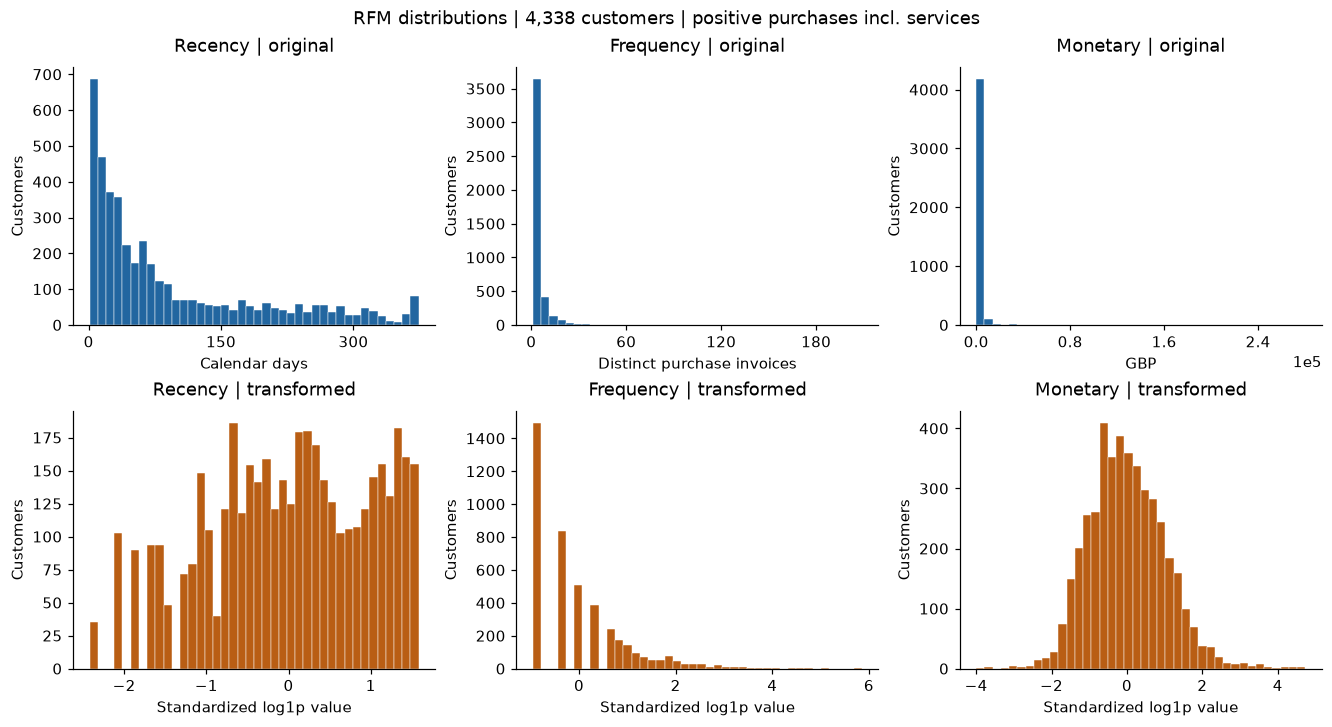

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), constrained_layout=True)
for index, (name, unit) in enumerate(zip(RFM, ["Calendar days", "Distinct purchase invoices", "GBP"])):
    axes[0, index].hist(features[name], bins=40, color=BLUE, edgecolor="white", linewidth=.3)
    axes[0, index].set(title=f"{name} | original", xlabel=unit, ylabel="Customers")
    axes[0, index].xaxis.set_major_locator(MaxNLocator(4))
    if name == "Monetary":
        axes[0, index].ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
    axes[1, index].hist(values[:, index], bins=40, color=ORANGE, edgecolor="white", linewidth=.3)
    axes[1, index].set(title=f"{name} | transformed", xlabel="Standardized log1p value", ylabel="Customers")
fig.suptitle(f"RFM distributions | {len(features):,} customers | positive purchases incl. services")
plt.show()

Phân phối Frequency và Monetary có đuôi phải dài ở thang gốc; log1p nén đuôi,
StandardScaler đưa ba biến về cùng thang đo. Phép biến đổi không loại khách ngoại lệ
và không làm dữ liệu tự động trở thành phân phối chuẩn.

## Kết quả

### 9. Chạy K-Means cho từng k

Chạy thật từng cấu hình trong notebook, không đọc metric cũ để thay cho fit.
Tính Silhouette và Davies–Bouldin trên toàn bộ khách đã fit, không lấy mẫu.
Giới hạn một thread giống CLI để tái lập; bước này có thể mất vài phút tùy máy.

In [9]:
fitted, metric_records = {}, []
with threadpool_limits(limits=1):
    for k in config["k_values"]:
        model = fit_kmeans(values, k=k, random_state=config["random_state"],
                           n_init=config["n_init"], max_iter=config["max_iter"])
        score = evaluate_clustering(values, model.labels_)
        fitted[k] = model
        metric_records.append({"k": k, "inertia": float(model.inertia_),
                               "n_iter": int(model.n_iter_), **score})
        print(f"k={k}: silhouette={score['silhouette']:.6f}; "
              f"Davies-Bouldin={score['davies_bouldin']:.6f}")
metrics = pd.DataFrame(metric_records)
selected_k = int(metrics.sort_values(["silhouette", "k"], ascending=[False, True]).iloc[0].k)
metrics["selected"] = metrics.k.eq(selected_k)
best_model = fitted[selected_k]
selected = metrics.loc[metrics.selected].iloc[0]
display(metrics[["k", "inertia", "silhouette", "davies_bouldin", "cluster_sizes", "selected"]].round(6))

k=2: silhouette=0.432509; Davies-Bouldin=0.891265


k=3: silhouette=0.337208; Davies-Bouldin=1.043655


k=4: silhouette=0.333918; Davies-Bouldin=1.017161


k=5: silhouette=0.318167; Davies-Bouldin=0.982312


k=6: silhouette=0.314590; Davies-Bouldin=1.021507


k=7: silhouette=0.310296; Davies-Bouldin=0.976234


k=8: silhouette=0.302062; Davies-Bouldin=0.991962


k=9: silhouette=0.281579; Davies-Bouldin=1.018582


k=10: silhouette=0.277079; Davies-Bouldin=1.021479


,k,inertia,silhouette,davies_bouldin,cluster_sizes,selected
0,2,6476.5069,0.4325,0.8913,"{0: 1668, 1: 2670}",True
1,3,4858.0785,0.3372,1.0437,"{0: 1700, 1: 1876, 2: 762}",False
2,4,3925.2745,0.3339,1.0172,"{0: 1177, 1: 889, 2: 731, 3: 1541}",False
3,5,3269.0748,0.3182,0.9823,"{0: 960, 1: 1167, 2: 344, 3: 859, 4: 1008}",False
4,6,2840.6540,0.3146,1.0215,"{0: 993, 1: 652, 2: 939, 3: 614, 4: 845, 5: 295}",False
5,7,2532.9847,0.3103,0.9762,"{0: 639, 1: 892, 2: 621, 3: 230, 4: 855, 5: 69...",False
6,8,2325.0754,0.3021,0.9920,"{0: 848, 1: 426, 2: 669, 3: 217, 4: 729, 5: 49...",False
7,9,2145.8392,0.2816,1.0186,"{0: 295, 1: 465, 2: 657, 3: 623, 4: 394, 5: 21...",False
8,10,1989.4049,0.2771,1.0215,"{0: 524, 1: 489, 2: 593, 3: 310, 4: 638, 5: 26...",False


### 10. Elbow, Silhouette và Davies–Bouldin

Inertia và Davies–Bouldin thấp hơn thường thuận lợi; Silhouette cao hơn thường thuận lợi.
Inertia giảm khi tăng k nên không dùng riêng tiêu chí “nhỏ nhất” để chọn k.
Đường đứt đánh dấu k được chọn theo quy tắc Silhouette trong cấu hình.

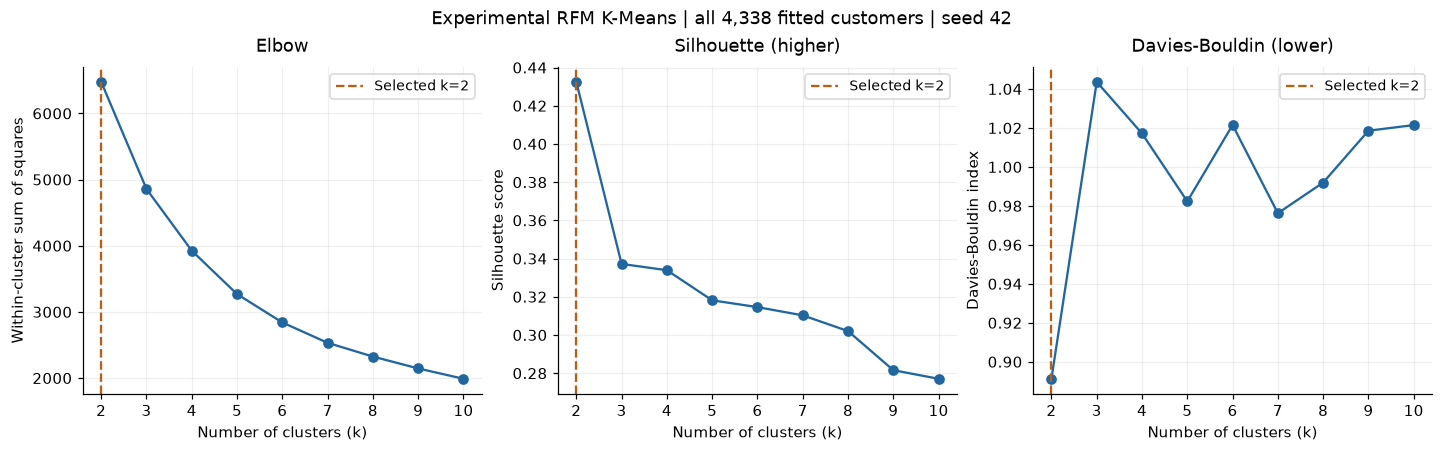

**Chọn k=2** trong dải 2–10: Silhouette **0.432509**, Davies–Bouldin **0.891265**. Đây là lựa chọn theo quy tắc đã định trên tập fit, chưa chứng minh tối ưu tuyệt đối hay khả năng dự báo.

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
metric_specs = [("inertia", "Elbow", "Within-cluster sum of squares"),
                ("silhouette", "Silhouette (higher)", "Silhouette score"),
                ("davies_bouldin", "Davies-Bouldin (lower)", "Davies-Bouldin index")]
for ax, (column, title, unit) in zip(axes, metric_specs):
    ax.plot(metrics.k, metrics[column], "o-", color=BLUE, linewidth=1.5)
    ax.axvline(selected_k, color=ORANGE, linestyle="--", label=f"Selected k={selected_k}")
    ax.set(title=title, xlabel="Number of clusters (k)", ylabel=unit, xticks=metrics.k)
    ax.grid(alpha=.2)
    ax.legend(fontsize=9)
fig.suptitle(f"Experimental RFM K-Means | all {len(features):,} fitted customers | seed {config['random_state']}")
plt.show()
display(Markdown(
    f"**Chọn k={selected_k}** trong dải {min(config['k_values'])}–{max(config['k_values'])}: "
    f"Silhouette **{selected.silhouette:.6f}**, Davies–Bouldin **{selected.davies_bouldin:.6f}**. "
    "Đây là lựa chọn theo quy tắc đã định trên tập fit, chưa chứng minh tối ưu tuyệt đối hay khả năng dự báo."
))

### 11. Gán cụm và lập hồ sơ khách hàng

Gán nhãn vào bảng RFM gốc để đọc được Recency theo ngày, Frequency theo hóa đơn
và Monetary theo GBP. Số Cluster là định danh tùy ý, không phải thứ hạng giá trị.
Dùng trung vị khi mô tả khách điển hình, tỷ trọng tổng Monetary để xem mức tập trung.

In [11]:
assignments = features.copy()
assignments["Cluster"] = best_model.labels_
profile = assignments.groupby("Cluster").agg(
    customers=("Customer ID", "size"),
    recency_mean=("Recency", "mean"), recency_median=("Recency", "median"),
    frequency_mean=("Frequency", "mean"), frequency_median=("Frequency", "median"),
    monetary_mean=("Monetary", "mean"), monetary_median=("Monetary", "median"),
    monetary_total=("Monetary", "sum"),
).reset_index()
profile["customer_share"] = profile.customers / len(assignments)
profile["monetary_share"] = profile.monetary_total / assignments.Monetary.sum()
assert int(profile.customers.sum()) == len(assignments)
np.testing.assert_allclose(profile[["customer_share", "monetary_share"]].sum(), [1, 1], atol=1e-12)
display(profile[["Cluster", "customers", "customer_share", "recency_median", "frequency_median",
                 "monetary_median", "monetary_total", "monetary_share"]].round(4))
display(assignments[["Customer ID", *RFM, "Cluster"]].head(8))

,Cluster,customers,customer_share,recency_median,frequency_median,monetary_median,monetary_total,monetary_share
0,0,1668,0.3845,17.0,6.0,2058.17,7.5656e+06,0.8513
1,1,2670,0.6155,96.0,1.0,362.01,1.3216e+06,0.1487


,Customer ID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,0
1,12347,3,7,4310.00,0
2,12348,76,4,1797.24,0
3,12349,19,1,1757.55,1
4,12350,311,1,334.40,1
5,12352,37,8,2506.04,0
6,12353,205,1,89.00,1
7,12354,233,1,1079.40,1


### 12. So sánh hồ sơ cụm ở đơn vị gốc

Mỗi ô dùng một đơn vị và thang trục riêng; so sánh các cụm trong cùng một ô.
Tất cả trục cột bắt đầu từ 0. Không so trực tiếp chiều cao giữa các ô khác đơn vị.

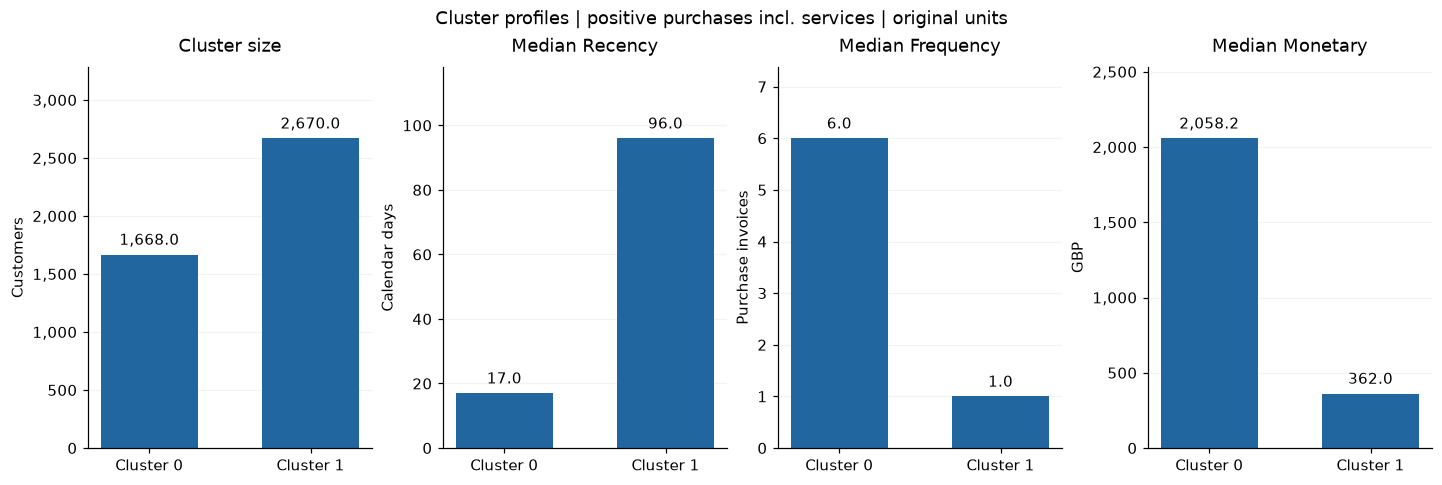

- **Cụm 0:** 1,668 khách (38.45%); trung vị R=17.0 ngày, F=6.0 hóa đơn, M=2,058.17 GBP; chiếm 85.13% tổng giá trị mua dương.
- **Cụm 1:** 2,670 khách (61.55%); trung vị R=96.0 ngày, F=1.0 hóa đơn, M=362.01 GBP; chiếm 14.87% tổng giá trị mua dương.

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4.3), constrained_layout=True)
profile_specs = [("customers", "Cluster size", "Customers"),
                 ("recency_median", "Median Recency", "Calendar days"),
                 ("frequency_median", "Median Frequency", "Purchase invoices"),
                 ("monetary_median", "Median Monetary", "GBP")]
labels = [f"Cluster {int(cluster)}" for cluster in profile.Cluster]
for ax, (column, title, unit) in zip(axes, profile_specs):
    bars = ax.bar(labels, profile[column], color=BLUE, width=.6)
    ax.bar_label(bars, labels=[f"{value:,.1f}" for value in profile[column]], padding=4, fontsize=10)
    ax.set(title=title, ylabel=unit)
    ax.set_ylim(0, float(profile[column].max()) * 1.23)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y", alpha=.15)
    ax.set_axisbelow(True)
fig.suptitle("Cluster profiles | positive purchases incl. services | original units")
plt.show()
profile_lines = [
    f"- **Cụm {int(row.Cluster)}:** {int(row.customers):,} khách ({row.customer_share:.2%}); "
    f"trung vị R={row.recency_median:,.1f} ngày, F={row.frequency_median:,.1f} hóa đơn, "
    f"M={row.monetary_median:,.2f} GBP; chiếm {row.monetary_share:.2%} tổng giá trị mua dương."
    for row in profile.itertuples(index=False)
]
display(Markdown("\n".join(profile_lines)))

### 13. Kiểm tra tái lập cùng seed

Fit lại cấu hình được chọn, đối chiếu nhãn, inertia và Adjusted Rand Index.
Kiểm tra này xác nhận tái lập với cùng cấu hình; không thay cho thử nhiều seed hoặc kiểm định theo thời gian.

In [13]:
with threadpool_limits(limits=1):
    repeated = fit_kmeans(values, k=selected_k, random_state=config["random_state"],
                          n_init=config["n_init"], max_iter=config["max_iter"])
reproducibility = {
    "labels_equal": bool(np.array_equal(best_model.labels_, repeated.labels_)),
    "adjusted_rand": float(adjusted_rand_score(best_model.labels_, repeated.labels_)),
    "inertia_difference": float(abs(best_model.inertia_ - repeated.inertia_)),
}
assert reproducibility["labels_equal"]
np.testing.assert_allclose(best_model.inertia_, repeated.inertia_, rtol=1e-12)
display(pd.DataFrame([reproducibility]))

,labels_equal,adjusted_rand,inertia_difference
0,True,1.0,0.0


### 14. Đối chiếu với kết quả CLI đã lưu

Nếu thư mục `experiments/baseline/` có workbook và assignments,
kiểm tra nguồn/cấu hình trước khi đối chiếu toàn bộ metric và RFM/nhãn từng khách.
Nếu chưa có artifact CLI, notebook vẫn chạy đầy đủ; chỉ bỏ qua phần so sánh này.
Không nạp lại `artifacts.joblib` để thay cho việc huấn luyện trong notebook.

In [14]:
workbook_path = baseline_dir / "results.xlsx"
assignments_path = baseline_dir / "assignments.csv.gz"
cli_comparison = "Chưa có đủ artifact CLI để đối chiếu; baseline đã tính từ raw ở các cell trên."
if workbook_path.is_file() and assignments_path.is_file():
    metadata_table = pd.read_excel(workbook_path, sheet_name="Metadata")
    stored_metadata = {row.item: json.loads(row.value_json)
                       for row in metadata_table.itertuples(index=False)}
    assert stored_metadata["raw_sha256"] == execution_record["raw_sha256"]
    assert stored_metadata["config"] == config, "Cấu hình CLI khác cấu hình notebook."
    assert stored_metadata["clean_rows"] == len(clean)
    assert stored_metadata["n_customers"] == len(features)
    assert stored_metadata["selected_k"] == selected_k

    stored_metrics = pd.read_excel(workbook_path, sheet_name="Metrics").sort_values("k")
    metric_columns = ["k", "inertia", "silhouette", "davies_bouldin"]
    pd.testing.assert_frame_equal(
        metrics.sort_values("k")[metric_columns].reset_index(drop=True),
        stored_metrics[metric_columns].reset_index(drop=True),
        check_dtype=False, check_exact=False, rtol=1e-10, atol=1e-10,
    )
    stored_assignments = pd.read_csv(assignments_path, dtype={"CustomerID": "string"})
    exported = assignments.rename(columns={"Customer ID": "CustomerID"})
    columns = ["CustomerID", *RFM, "Cluster"]
    pd.testing.assert_frame_equal(
        exported[columns].sort_values("CustomerID").reset_index(drop=True),
        stored_assignments[columns].sort_values("CustomerID").reset_index(drop=True),
        check_dtype=False, check_exact=False, rtol=1e-10, atol=1e-10,
    )
    cli_comparison = (f"Đã khớp {len(metrics)} cấu hình k và RFM/nhãn của toàn bộ "
                      f"{len(assignments):,} khách với artifact CLI cùng raw/cấu hình.")
print(cli_comparison)

Đã khớp 9 cấu hình k và RFM/nhãn của toàn bộ 4,338 khách với artifact CLI cùng raw/cấu hình.


### 15. Kiểm tra dữ liệu và artifact không bị thay đổi

Các cell trước chỉ tính trong bộ nhớ. Đối chiếu lại danh sách file và SHA-256
để xác nhận raw, processed và kết quả CLI hiện có được giữ nguyên.

In [15]:
current_protected = [RAW_PATH, *sorted((project / "data/processed").rglob("*")),
                     *sorted(baseline_dir.rglob("*"))]
protected_after = {p: sha256_of(p) for p in current_protected if p.is_file()}
assert protected_after == protected_before, "Dữ liệu hoặc artifact trên đĩa đã thay đổi."
print(f"Đạt: {len(protected_after)} file raw/processed/baseline giữ nguyên SHA-256.")
print("Thời điểm chạy (UTC+7):", execution_record["executed_at"])

Đạt: 11 file raw/processed/baseline giữ nguyên SHA-256.
Thời điểm chạy (UTC+7): 2026-11-06T23:29:55.020558+07:00


## Kết luận và giới hạn

Bảng và biểu đồ phía trên là kết quả fit thật từ raw trong phiên notebook này.
Có thể xem lại mà không chạy kernel vì output đã được lưu trong file `.ipynb`.

In [16]:
display(Markdown(
    f"Từ **{len(raw):,} dòng raw**, chính sách thử nghiệm giữ **{len(clean):,} dòng mua**, "
    f"tổng hợp **{len(features):,} khách** và chọn **k={selected_k}** trong dải đã khảo sát. "
    f"Silhouette đạt **{selected.silhouette:.6f}**, Davies–Bouldin **{selected.davies_bouldin:.6f}**.\n\n"
    f"{cli_comparison}\n\n"
    "Hồ sơ cụm mô tả giá trị mua lịch sử. Chưa có nhãn giá trị cao chính thức, "
    "holdout độc lập, đánh giá nhiều seed hay bằng chứng hiệu quả marketing. "
    "Cần nhóm chốt chính sách trước khi xem đây là kết quả chính thức; "
    "Hierarchical, DBSCAN và dự báo tương lai nằm ngoài notebook baseline này."
))

Từ **541,909 dòng raw**, chính sách thử nghiệm giữ **392,692 dòng mua**, tổng hợp **4,338 khách** và chọn **k=2** trong dải đã khảo sát. Silhouette đạt **0.432509**, Davies–Bouldin **0.891265**.

Đã khớp 9 cấu hình k và RFM/nhãn của toàn bộ 4,338 khách với artifact CLI cùng raw/cấu hình.

Hồ sơ cụm mô tả giá trị mua lịch sử. Chưa có nhãn giá trị cao chính thức, holdout độc lập, đánh giá nhiều seed hay bằng chứng hiệu quả marketing. Cần nhóm chốt chính sách trước khi xem đây là kết quả chính thức; Hierarchical, DBSCAN và dự báo tương lai nằm ngoài notebook baseline này.